# 1-01 무상증자 이벤트 스터디 — 결정 공시 전후 주가 반응

**질문 예시:** "무상증자 발표하면 주가 오르나?", "1주당 1주씩 주는 큰 무상증자일수록 더 오르나?", "올해랑 작년이랑 반응이 달라?"

예전 Streamlit 앱(`krxnewsscrap/bonus_issue.py`)은 DART 무상증자결정과 일별 시세를 DB에 쌓아 두고
이사회결의일 기준 당일·전후 1일 수익률을 발행비율·연도별로 봤습니다. 그 DB는 이제 없어서
**KIND 공시 + KRX 시세**로 다시 만들었습니다.

| 항목 | 어디서 |
|---|---|
| 무상증자결정 공시와 **공시 시각** | KIND 공시 상세검색 `disclosure_details`(공시제목 `무상증자결정`), 원본·정정 모두 받아 정정 표시로 구분 |
| 발행비율(1주당 신주배정 주식수)·신주배정기준일 | 공시 **본문** 표 (`resolve_content_url` → 본문 HTML) |
| 주가 | KRX `individual_price_trend` **수정주가** (krx-data-api, 로그인 필요) |
| 시장 수익률 | KRX `equity_index` 코스피·코스닥 지수 → 시장 대비 **초과수익** |
| 종목코드 ↔ 표준코드 | KRX `all_stock_price` 하루치(전 종목 한 번 호출) |

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/krx-kind-data-api/blob/main/scenarios/1_disclosure_events/01_bonus_issue_event_study.ipynb)

## 0. 준비
KIND(공시)는 로그인 없이 되지만, KRX 정보데이터시스템(시세·지수)은 2026-09부터 로그인이 필요합니다. Colab 왼쪽 🔑(Secrets)에 `KRX_ID`, `KRX_PW`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 패키지 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install "git+https://github.com/beaten-by-the-market/krx-kind-data-api.git" \
        "git+https://github.com/beaten-by-the-market/krx-data-api.git" koreanize-matplotlib

In [2]:
# ── KIND·KRX 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# KIND(kind.krx.co.kr, 공시)는 로그인 없이 됩니다.
# KRX 정보데이터시스템(data.krx.co.kr, 시세·지수)은 2026-09부터 로그인이 필요합니다.
#   Colab: 왼쪽 🔑(Secrets)에 KRX_ID, KRX_PW 를 넣고 "노트북 액세스"를 켜세요.
#   로컬: 환경변수 KRX_ID/KRX_PW 또는 .env (krx-data-api 가 작업 폴더와 자기 레포의 .env 를 읽음).
# 아이디·비밀번호 값은 출력하지 않습니다.
import io, os, re, sys, time
from datetime import date, datetime, timedelta

import numpy as np
import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata
    for _k in ("KRX_ID", "KRX_PW"):
        try:
            _v = userdata.get(_k)
        except Exception:
            _v = None
        if _v:
            os.environ[_k] = _v
    if not (os.environ.get("KRX_ID") and os.environ.get("KRX_PW")):
        print("⚠️ Colab Secrets 에 KRX_ID / KRX_PW 가 없습니다. 시세·지수 호출이 LOGOUT 오류로 실패합니다.")

import krx_kind_data_api as kind
from krx_data_api import fetch as krx_fetch

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

# ── KIND 호출 (분당 50요청 안쪽으로) ──────────────────────────────────────
_KIND_GAP = 1.2          # 초. KIND는 과한 호출에 민감하다(README: 분당 50요청 이하)
_kind_last = [0.0]
_KIND_SESSION = requests.Session()


def _kind_wait():
    gap = time.time() - _kind_last[0]
    if gap < _KIND_GAP:
        time.sleep(_KIND_GAP - gap)
    _kind_last[0] = time.time()


def kind_fetch(name, **params):
    """krx_kind_data_api.fetch + 호출 간격 조절."""
    _kind_wait()
    return kind.fetch(name, session=_KIND_SESSION, **params)


def disclosures(date_from, date_to, **params):
    """KIND 공시 상세검색(disclosure_details)을 월 단위로 끊어 모두 받는다.
    긴 기간을 한 번에 주면 KIND가 오류 없이 0건을 돌려주므로 월별로 나누고, 100건이 넘으면 페이지를 넘긴다.
    params 예: reportNm="무상증자결정", disclosureType="배당", lastReport=""(원본·정정 모두).
    결과의 `시간`은 공시 시각(Timestamp), `정정`/`이후정정`은 정정 표시."""
    parts = []
    for m in pd.period_range(pd.Timestamp(date_from), pd.Timestamp(date_to), freq="M"):
        s = max(m.start_time, pd.Timestamp(date_from)).strftime("%Y-%m-%d")
        e = min(m.end_time, pd.Timestamp(date_to)).strftime("%Y-%m-%d")
        page = 1
        while True:
            df = kind_fetch("disclosure_details", fromDate=s, toDate=e, pageIndex=str(page),
                            currentPageSize="100", **params)
            parts.append(df)
            if len(df) < 100:
                break
            page += 1
    out = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
    if out.empty:
        return out
    out["시간"] = pd.to_datetime(out["시간"], errors="coerce")
    return (out.drop(columns=["번호"]).drop_duplicates("접수번호")
               .sort_values("시간").reset_index(drop=True))


def disclosure_tables(acptno):
    """접수번호 → 공시 본문의 표 목록(pd.read_html). 정정된 공시는 최종(정정) 본문이 온다.
    resolve_content_url 은 목차(_toc.htm)를 주는 경우가 있어 본문(.htm)으로 바꿔 읽는다. 요청 3회."""
    _kind_wait()
    url = kind.resolve_content_url(acptno, session=_KIND_SESSION).replace("_toc.htm", ".htm")
    _kind_wait()
    r = _KIND_SESSION.get(url, timeout=30)
    r.raise_for_status()
    html = r.content.decode("utf-8", "replace")
    try:
        return pd.read_html(io.StringIO(html))
    except ValueError:
        return []


# ── KRX 시세·지수 (krx-data-api, 로그인 필요) ────────────────────────────
INDEX_CODES = {"KOSPI": ("1", "001"), "KOSDAQ": ("2", "001")}


def _num(s):
    return pd.to_numeric(s.astype(str).str.replace(",", ""), errors="coerce")


def index_close(name, date_from, date_to):
    """KRX 지수 일별 종가(Series, index=날짜). name: KOSPI / KOSDAQ."""
    a, b = INDEX_CODES[name]
    df = krx_fetch("equity_index", indIdx=a, indIdx2=b,
                   strtDd=pd.Timestamp(date_from).strftime("%Y%m%d"),
                   endDd=pd.Timestamp(date_to).strftime("%Y%m%d"))
    s = pd.Series(_num(df["종가"]).values, index=pd.to_datetime(df["일자"]), name=name)
    return s.sort_index()


def stock_snapshot(day):
    """하루치 전 종목 시세(all_stock_price, JSON 영문 코드). 휴장일이면 직전 거래일 값이 온다.
    ISU_SRT_CD(단축코드)·ISU_CD(표준코드 KR7…)·ISU_ABBRV·MKT_NM·TDD_CLSPRC(원주가)·LIST_SHRS 등."""
    df = krx_fetch("all_stock_price", trdDd=pd.Timestamp(day).strftime("%Y%m%d"))
    for c in ("TDD_CLSPRC", "FLUC_RT", "ACC_TRDVOL", "ACC_TRDVAL", "MKTCAP", "LIST_SHRS"):
        if c in df:
            df[c] = _num(df[c])
    return df


def price_trend(isu_cd, date_from, date_to, adjusted=True):
    """개별종목 일별 시세(individual_price_trend, CSV 한글 컬럼). isu_cd 는 표준코드(KR7…).
    adjusted=True 면 수정주가(오늘 기준), False 면 원주가. index=날짜."""
    df = krx_fetch("individual_price_trend", isuCd=isu_cd,
                   strtDd=pd.Timestamp(date_from).strftime("%Y%m%d"),
                   endDd=pd.Timestamp(date_to).strftime("%Y%m%d"),
                   adjusted_price=adjusted)
    if df.empty:
        return df
    df.index = pd.to_datetime(df.pop("일자"))
    return df.sort_index()


def reaction_day(ts, days, cutoff="15:30"):
    """공시 시각 → 반응 첫 거래일(D0)의 위치(days 안의 정수 인덱스).
    장 마감(cutoff) 이후 공시는 다음 거래일, 휴장일 공시는 다음 거래일이 D0."""
    hh, mm = map(int, cutoff.split(":"))
    day = ts.normalize()
    if ts.hour * 60 + ts.minute >= hh * 60 + mm:
        day += pd.Timedelta(days=1)
    pos = days.searchsorted(day)
    return int(pos) if pos < len(days) else None


def pct(x, digits=1):
    return "-" if x is None or pd.isna(x) else f"{x * 100:+.{digits}f}%"


PRICE_NOTICE = ("※ 주가는 KRX 수정주가(individual_price_trend, 오늘 기준)입니다. 무상증자·분할의 권리락으로 생기는 "
                "기계적 하락은 소급 반영돼 수익률에 섞이지 않습니다. 배당은 반영하지 않습니다.")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("KIND·KRX 준비 완료", "(Colab)" if IN_COLAB else "(로컬)",
      "| KRX 로그인 정보:", "있음" if os.environ.get("KRX_ID") and os.environ.get("KRX_PW") else "없음")

KIND·KRX 준비 완료 (로컬) | KRX 로그인 정보: 있음


In [3]:
START, END = "2025-01-01", "2026-11-14"   # 공시 기간. D+5 시세가 있도록 끝은 기준일 1주 전
ASOF = "2026-11-24"                        # 시세 기준일
print(PRICE_NOTICE)

※ 주가는 KRX 수정주가(individual_price_trend, 오늘 기준)입니다. 무상증자·분할의 권리락으로 생기는 기계적 하락은 소급 반영돼 수익률에 섞이지 않습니다. 배당은 반영하지 않습니다.


## 1. 무상증자결정 공시 모으기
- KIND 상세검색은 기간이 길면 오류 없이 0건을 주므로 **월 단위**로 끊어 받습니다(헬퍼 `disclosures`).
- `lastReport=""`로 원본과 정정을 모두 받은 뒤, 제목 앞 `[정정]` 표시가 있는 **정정공시는 뺍니다.**
  시장이 처음 반응하는 건 원본 공시이기 때문입니다. 바뀐 조건(비율·기준일)은 2절에서 최종 본문으로 반영합니다.
- `무상증자결정(자회사의 주요경영사항)`처럼 **자회사·종속회사** 공시도 뺍니다(공시 회사 자신의 증자가 아님).
- 같은 검색어로 `유무상증자결정`은 잡히지 않습니다(유상증자가 섞인 다른 사건이라 의도대로입니다).

In [4]:
raw = disclosures(START, END, reportNm="무상증자결정", lastReport="")
is_sub = raw["공시제목"].str.contains("주요경영사항")
print(f"받은 공시 {len(raw)}건 = 원본 {(~raw['정정']).sum()} + 정정 {raw['정정'].sum()}")
print(f"  그중 자회사·종속회사 공시 {is_sub.sum()}건, 코넥스 {(raw['시장'] == '코넥스').sum()}건")
ev = raw[~raw["정정"] & ~is_sub & raw["시장"].isin(["유가증권", "코스닥"])].reset_index(drop=True)
print(f"→ 분석 대상 원본 공시 {len(ev)}건 (나중에 정정된 원본 {ev['이후정정'].sum()}건 포함)")
ev[["시간", "시장", "회사명", "공시제목", "접수번호", "이후정정"]].tail(8)

받은 공시 114건 = 원본 80 + 정정 34
  그중 자회사·종속회사 공시 3건, 코넥스 0건
→ 분석 대상 원본 공시 77건 (나중에 정정된 원본 23건 포함)


,시간,시장,회사명,공시제목,접수번호,이후정정
69,2026-09-02 10:58:00,코스닥,미트박스,무상증자결정,20260902000120,False
70,2026-09-14 10:22:00,코스닥,코나아이,무상증자결정,20260914000090,False
71,2026-09-29 12:16:00,코스닥,프로티아,무상증자결정,20260929000267,False
72,2026-10-01 11:34:00,유가증권,MH에탄올,무상증자결정,20261001000160,False
73,2026-10-06 13:29:00,유가증권,케이아이이,무상증자결정,20261006000186,False
74,2026-10-07 11:17:00,코스닥,알파칩스,무상증자결정,20261007000162,False
75,2026-11-06 15:14:00,유가증권,고려제강,무상증자결정,20261106000557,False
76,2026-11-10 13:28:00,코스닥,핑거스토리,무상증자결정,20261110000288,False


## 2. 공시 본문에서 발행비율·기준일 읽기
KIND 목록에는 비율이 없어서 공시 본문 표를 읽습니다. 공시 1건당 요청 3회(뷰어 → 본문 주소 → 본문)라
KIND 권장 속도(분당 50요청)에 맞추면 100건에 6분쯤 걸립니다.
원본 접수번호로 열어도 KIND는 **최종 정정본**을 보여 주므로, 비율·기준일은 정정이 반영된 값입니다.

- **발행비율** = `5. 1주당 신주배정 주식수`(보통주). 1이면 1주당 1주(주식 수 2배).
- **신주배정기준일**로 권리락일(기준일 직전 거래일)을 계산해 4절에서 따로 봅니다.

In [5]:
def _rows(tables):
    for t in tables or []:
        if t.shape[1] < 2:
            continue
        for vals in t.astype(str).values.tolist():
            yield vals[0].replace(" ", ""), vals[1].replace(" ", ""), vals[-1]

def body_field(tables, label, common_only=False):
    for c0, c1, v in _rows(tables):
        if label in c0 and (not common_only or "보통" in c1):
            return v
    return None

def to_num(v):
    m = re.search(r"-?[\d,]*\.?\d+", str(v or "").replace(",", ""))
    return float(m.group()) if m else np.nan

def to_date(v):
    m = re.search(r"(\d{4})\D+(\d{1,2})\D+(\d{1,2})", str(v or ""))
    return pd.Timestamp(int(m[1]), int(m[2]), int(m[3])) if m else pd.NaT

t0 = time.time()
info = []
for a in ev["접수번호"]:
    try:
        tb = disclosure_tables(a)
    except Exception as e:          # 본문을 못 읽으면 비율 없이 남긴다
        print("본문 실패", a, type(e).__name__)
        tb = []
    info.append({
        "접수번호": a,
        "발행비율": to_num(body_field(tb, "1주당신주배정주식수", common_only=True)),
        "신주수": to_num(body_field(tb, "신주의종류와수", common_only=True)),
        "증자전주식수": to_num(body_field(tb, "증자전발행주식총수", common_only=True)),
        "신주배정기준일": to_date(body_field(tb, "신주배정기준일")),
        "상장예정일": to_date(body_field(tb, "신주의상장예정일")),
    })
ev = ev.merge(pd.DataFrame(info), on="접수번호", how="left")
print(f"본문 {len(ev)}건 읽음 ({time.time() - t0:.0f}초). 발행비율을 못 읽은 공시 {ev['발행비율'].isna().sum()}건")
ev["발행비율"].describe().round(2)

본문 77건 읽음 (185초). 발행비율을 못 읽은 공시 0건


count    77.00
mean      1.11
std       0.79
min       0.04
25%       0.50
50%       1.00
75%       2.00
max       3.00
Name: 발행비율, dtype: float64

## 3. 시세 붙이고 반응일(D0) 정하기
- **D0** = 공시 후 첫 거래일. 장 마감(15:30) 이후 공시는 다음 거래일이 D0입니다(시간외 거래는 무시).
- 주가는 **수정주가**입니다. 원주가로 재면 권리락일에 주가가 1/(1+비율)로 떨어져(1주당 1주면 반토막)
  공시 후 며칠 창에 권리락이 끼면 수익률이 엉망이 됩니다. 아래 표가 그 예입니다.
- 일별 시세는 기간 조회가 종목별 화면(`individual_price_trend`)뿐이라 **사건마다 1번** 부릅니다.
  전 종목 시세(`all_stock_price`)는 하루치라 사건 창을 다 덮으려면 거래일 수백 번을 불러야 해서 더 느립니다.

In [6]:
kospi = index_close("KOSPI", "2024-11-01", ASOF)
kosdaq = index_close("KOSDAQ", "2024-11-01", ASOF)
days = kospi.index
mkt_index = {"유가증권": kospi, "코스닥": kosdaq}

snap = stock_snapshot(ASOF)                     # 종목코드 → 표준코드(KR7…)
isin = snap.set_index("ISU_SRT_CD")["ISU_CD"]
ev["종목코드"] = ev["회사코드"].str.strip() + "0"
ev["표준코드"] = ev["종목코드"].map(isin)
ev["D0_pos"] = [reaction_day(t, days) for t in ev["시간"]]
ev["반응일"] = [days[int(p)] if pd.notna(p) else pd.NaT for p in ev["D0_pos"]]


def ex_pos_of(rd):
    """신주배정기준일 → 권리락일 위치. 기준일(휴장이면 직전 거래일)의 바로 전 거래일(T+2 결제).
    기준일이 아직 오지 않았으면 None."""
    if pd.isna(rd) or not (days[0] <= rd <= days[-1]):
        return None
    return int(days.searchsorted(rd, side="right")) - 2


ev["권리락_pos"] = [ex_pos_of(rd) for rd in ev["신주배정기준일"]]
ev["권리락일자"] = [days[int(p)] if pd.notna(p) else pd.NaT for p in ev["권리락_pos"]]
miss = ev[ev["표준코드"].isna()]
print(f"표준코드를 못 찾은 사건 {len(miss)}건(상장폐지·코드변경 추정):", ", ".join(miss["회사명"]) or "-")

# 원주가 vs 수정주가: 권리락일에 무슨 일이 생기나 (거래정지 없이 정상 거래된 1주당 1주 사례)
DEMO = "비츠로셀"
cand = ev.dropna(subset=["표준코드", "권리락일자"])
ex_demo = (cand[cand["회사명"] == DEMO] if (cand["회사명"] == DEMO).any() else cand.sort_values("발행비율")).iloc[-1]
q = int(ex_demo["권리락_pos"])
a_ = price_trend(ex_demo["표준코드"], days[q - 3], days[q + 2], adjusted=False)["종가"]
b_ = price_trend(ex_demo["표준코드"], days[q - 3], days[q + 2], adjusted=True)["종가"]
print(f"\n{ex_demo['회사명']} — 1주당 {ex_demo['발행비율']:g}주, 신주배정기준일 {ex_demo['신주배정기준일'].date()}, "
      f"권리락일 {ex_demo['권리락일자'].date()}")
pd.DataFrame({"원주가 종가": a_, "원주가 수익률": a_.pct_change().map(pct),
              "수정주가 종가": b_, "수정주가 수익률": b_.pct_change().map(pct)})

표준코드를 못 찾은 사건 0건(상장폐지·코드변경 추정): -



비츠로셀 — 1주당 1주, 신주배정기준일 2025-12-11, 권리락일 2025-12-10


,원주가 종가,원주가 수익률,수정주가 종가,수정주가 수익률
일자,,,,
2025-12-05,35400,-,17866,-
2025-12-08,35600,+0.6%,17966,+0.6%
2025-12-09,38500,+8.1%,19430,+8.1%
2025-12-10,17820,-53.7%,17820,-8.3%
2025-12-11,17360,-2.6%,17360,-2.6%
2025-12-12,17830,+2.7%,17830,+2.7%


In [7]:
WIN_PRE, WIN_POST = 20, 10      # 경로 그림용 창(거래일)
rows, paths = [], {}
t0 = time.time()
for _, e in ev.dropna(subset=["표준코드", "반응일"]).iterrows():
    p = int(e["D0_pos"])
    if p - WIN_PRE - 1 < 0:
        continue
    ex_pos = None if pd.isna(e["권리락_pos"]) else int(e["권리락_pos"])
    last = min(len(days) - 1, max(p + WIN_POST, (ex_pos or 0) + 1))
    px = price_trend(e["표준코드"], days[p - WIN_PRE - 1], days[last])
    if px.empty:
        continue
    c = px["종가"].astype(float).reindex(days[p - WIN_PRE - 1:last + 1]).ffill()
    m = mkt_index[e["시장"]].reindex(c.index).ffill()
    o = p - WIN_PRE - 1                                   # c 안에서의 위치 = 전체 위치 - o

    def r(s, a, b):
        a, b = a - o, b - o
        return s.iloc[b] / s.iloc[a] - 1 if 0 <= a < len(s) and 0 <= b < len(s) else np.nan

    rec = {"접수번호": e["접수번호"]}
    for col, (a, b) in {"발표 전 20일": (p - 21, p - 1), "D0": (p - 1, p),
                        "D-1~D+1": (p - 2, p + 1), "D0~D+5": (p - 1, p + 5)}.items():
        rec[col] = r(c, a, b)
        rec[col + " 초과"] = rec[col] - r(m, a, b)
    if ex_pos is not None and ex_pos > p + 1:
        rec["권리락일"] = r(c, ex_pos - 1, ex_pos)
        rec["권리락일 초과"] = rec["권리락일"] - r(m, ex_pos - 1, ex_pos)
        rec["D0→권리락 거래일"] = ex_pos - p
    rows.append(rec)
    ar = (c.pct_change() - m.pct_change()).iloc[1:]          # 일별 초과수익, D-20 … D+10
    seg = ar.iloc[:WIN_PRE + WIN_POST + 1]
    if len(seg) == WIN_PRE + WIN_POST + 1:
        paths[e["접수번호"]] = seg.values
res = ev.merge(pd.DataFrame(rows), on="접수번호", how="inner")
res["연도"] = res["반응일"].dt.year
print(f"시세를 붙인 사건 {len(res)}건 ({time.time() - t0:.0f}초)")

시세를 붙인 사건 77건 (47초)


## 4. 결과
### 4-1. 전체 분포
- **D0**: D−1 종가 → D0 종가 (발표 당일 반응)
- **D-1~D+1**: D−2 종가 → D+1 종가 (예전 앱의 "전후1일 수익률"과 같은 3일 창)
- **D0~D+5**: D−1 종가 → D+5 종가 (발표 후 한 주)
- **초과** = 같은 구간 종목 수익률 − 소속 시장 지수(코스피/코스닥) 수익률

In [8]:
COLS = ["발표 전 20일", "D0", "D-1~D+1", "D0~D+5", "권리락일"]

def summary(df, cols):
    out = {}
    for c in cols:
        x = df[c].dropna()
        out[c] = {"n": len(x), "평균": pct(x.mean()), "중앙값": pct(x.median()),
                  "상승 비율": f"{(x > 0).mean() * 100:.0f}%" if len(x) else "-",
                  "하위 25%": pct(x.quantile(.25)), "상위 25%": pct(x.quantile(.75))}
    return pd.DataFrame(out).T

print("시장 대비 초과수익")
summary(res, [c + " 초과" for c in COLS])

시장 대비 초과수익


,n,평균,중앙값,상승 비율,하위 25%,상위 25%
발표 전 20일 초과,76,+1.9%,+0.8%,58%,-9.3%,+10.7%
D0 초과,77,+11.9%,+9.6%,92%,+3.6%,+19.0%
D-1~D+1 초과,77,+16.1%,+13.4%,95%,+7.0%,+22.2%
D0~D+5 초과,77,+18.7%,+16.9%,94%,+6.2%,+30.0%
권리락일 초과,75,+2.2%,-2.5%,40%,-5.6%,+6.8%


In [9]:
print("원 수익률 (시장 미조정)")
summary(res, COLS)

원 수익률 (시장 미조정)


,n,평균,중앙값,상승 비율,하위 25%,상위 25%
발표 전 20일,76,+2.4%,+0.9%,51%,-9.6%,+15.4%
D0,77,+12.2%,+9.8%,94%,+4.2%,+17.9%
D-1~D+1,77,+16.1%,+13.3%,94%,+6.6%,+21.7%
D0~D+5,77,+18.3%,+12.8%,94%,+7.0%,+30.0%
권리락일,75,+2.6%,-2.0%,40%,-6.5%,+9.0%


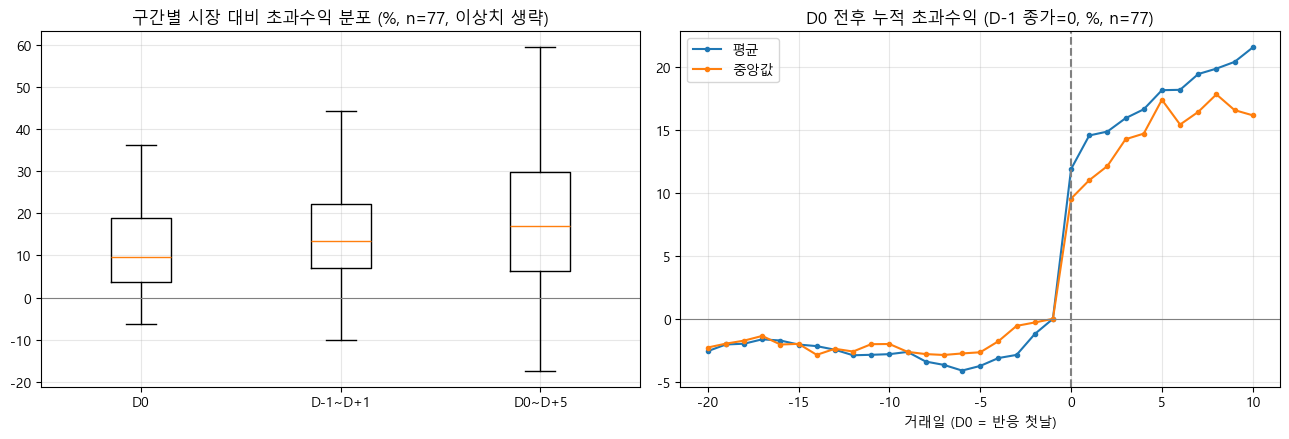

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
box_cols = ["D0 초과", "D-1~D+1 초과", "D0~D+5 초과"]
axes[0].boxplot([res[c].dropna() * 100 for c in box_cols], showfliers=False)
axes[0].set_xticks(range(1, len(box_cols) + 1), [c.replace(" 초과", "") for c in box_cols])
axes[0].axhline(0, color="gray", lw=.8)
axes[0].set_title(f"구간별 시장 대비 초과수익 분포 (%, n={len(res)}, 이상치 생략)")
axes[0].grid(alpha=.3)

car = pd.DataFrame(paths).T
car.columns = range(-WIN_PRE, WIN_POST + 1)
cum = (car.cumsum(axis=1).sub(car.loc[:, :-1].sum(axis=1), axis=0)) * 100   # D-1 종가 기준 0
axes[1].plot(cum.columns, cum.mean(), marker="o", ms=3, label="평균")
axes[1].plot(cum.columns, cum.median(), marker="o", ms=3, label="중앙값")
axes[1].axvline(0, color="gray", ls="--"); axes[1].axhline(0, color="gray", lw=.8)
axes[1].set_title(f"D0 전후 누적 초과수익 (D-1 종가=0, %, n={len(cum)})")
axes[1].set_xlabel("거래일 (D0 = 반응 첫날)"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout()

### 4-2. 연도별
평균은 소수의 급등 종목에 끌려가기 쉬워 **중앙값과 상승 비율**을 함께 봅니다.

In [11]:
def by_group(df, key, cols=("D0 초과", "D-1~D+1 초과", "D0~D+5 초과")):
    g = df.groupby(key, observed=True)
    out = pd.DataFrame({"사건 수": g.size()})
    for c in cols:
        out[c + " 평균"] = g[c].mean().map(pct)
        out[c + " 중앙값"] = g[c].median().map(pct)
    out["D0 초과 상승 비율"] = g["D0 초과"].apply(lambda x: f"{(x > 0).mean() * 100:.0f}%")
    return out

by_group(res, "연도")

,사건 수,D0 초과 평균,D0 초과 중앙값,D-1~D+1 초과 평균,D-1~D+1 초과 중앙값,D0~D+5 초과 평균,D0~D+5 초과 중앙값,D0 초과 상승 비율
연도,,,,,,,,
2025,42,+10.0%,+6.9%,+13.8%,+10.6%,+19.1%,+14.2%,93%
2026,35,+14.2%,+11.9%,+18.9%,+16.0%,+18.1%,+18.1%,91%


### 4-3. 발행비율 구간별
1주당 신주배정 주식수로 나눕니다. 먼저 구간별 표, 다음 그림은 예전 앱처럼 비율과 D0 초과수익의 산점도(연도별 색)입니다.

In [12]:
res["비율 구간"] = pd.cut(res["발행비율"], [0, 0.3, 0.99, 1.0, 100],
                       labels=["0.3주 이하", "0.3~1주 미만", "1주", "1주 초과(2~3주)"])
by_group(res, "비율 구간")

,사건 수,D0 초과 평균,D0 초과 중앙값,D-1~D+1 초과 평균,D-1~D+1 초과 중앙값,D0~D+5 초과 평균,D0~D+5 초과 중앙값,D0 초과 상승 비율
비율 구간,,,,,,,,
0.3주 이하,15,+7.2%,+2.8%,+9.6%,+4.6%,+14.1%,+16.2%,80%
0.3~1주 미만,11,+10.3%,+9.7%,+14.3%,+10.9%,+9.8%,+6.5%,100%
1주,30,+13.2%,+11.1%,+18.9%,+15.1%,+19.8%,+19.2%,93%
1주 초과(2~3주),21,+14.3%,+13.1%,+17.8%,+16.2%,+25.0%,+22.4%,95%


발행비율과 D0 초과수익의 순위상관(스피어만): 0.28


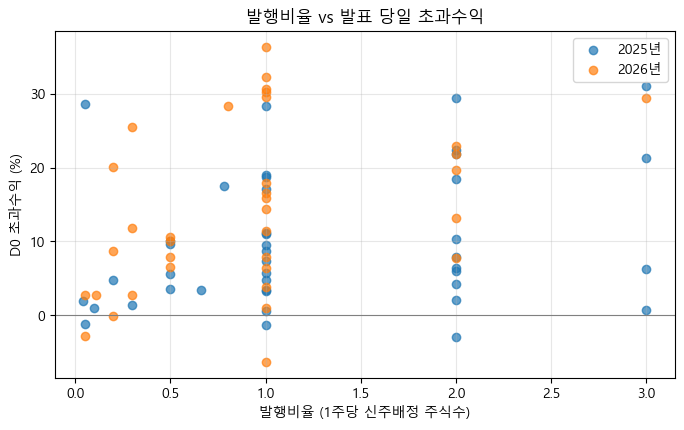

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for y, g in res.groupby("연도"):
    ax.scatter(g["발행비율"], g["D0 초과"] * 100, alpha=.7, label=f"{y}년")
ax.axhline(0, color="gray", lw=.8)
ax.set_xlabel("발행비율 (1주당 신주배정 주식수)"); ax.set_ylabel("D0 초과수익 (%)")
ax.set_title("발행비율 vs 발표 당일 초과수익"); ax.legend(); ax.grid(alpha=.3)
print("발행비율과 D0 초과수익의 순위상관(스피어만):",
      round(res[["발행비율", "D0 초과"]].corr(method="spearman").iloc[0, 1], 2))

### 4-4. 반응이 컸던 사건
표의 `상세URL`은 KIND 공시 뷰어 링크입니다.

In [14]:
show = res.sort_values("D0 초과", ascending=False)
cols = ["반응일", "시장", "회사명", "발행비율", "D0 초과", "D-1~D+1 초과", "D0~D+5 초과", "상세URL"]
fmt = lambda d: d[cols].assign(**{c: d[c].map(pct) for c in cols if "초과" in c})
pd.concat([fmt(show.head(5)), fmt(show.tail(5))])

,반응일,시장,회사명,발행비율,D0 초과,D-1~D+1 초과,D0~D+5 초과,상세URL
66,2026-07-16,유가증권,비비안,1.00,+36.3%,+23.2%,-17.4%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...
74,2026-10-07,코스닥,알파칩스,1.00,+32.3%,+27.7%,+47.3%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...
40,2025-12-23,코스닥,뷰티스킨,3.00,+31.0%,+30.8%,+24.6%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...
42,2026-01-14,코스닥,아진엑스텍,1.00,+30.7%,+50.8%,+50.9%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...
53,2026-05-13,코스닥,코미코,1.00,+30.2%,+22.0%,+12.5%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...
33,2025-11-12,코스닥,시노펙스,0.05,-1.2%,-2.1%,-0.2%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...
29,2025-11-03,코스닥,드림시큐리티,1.00,-1.3%,+5.2%,+10.9%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...
54,2026-05-21,유가증권,셀트리온,0.05,-2.7%,+1.0%,-10.1%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...
7,2025-04-15,코스닥,블루엠텍,2.00,-2.9%,+13.3%,+10.1%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...
61,2026-06-29,코스닥,큐리오시스,1.00,-6.3%,-10.0%,+1.7%,https://kind.krx.co.kr/common/disclsviewer.do?method=sea...


## 결과 읽는 법과 한계
- **D0와 D0~D+5를 비교**하세요. D0~D+5가 더 크면 첫날 이후에도 더 올랐다는 뜻이고(이 표본이 그렇습니다), 작으면 첫날 과열이 되돌려진 것입니다.
  첫날 상한가(+30%)에 막힌 종목은 다음 날 나머지가 반영되므로 D-1~D+1 창도 같이 봅니다.
- **발표 전 20일**이 이미 크게 올라 있으면 정보가 새었거나, 주가가 오른 회사가 무상증자를 택한 것(역인과)일 수 있습니다.
- 초과수익은 **시장조정 모형**(종목 − 소속 시장 지수)입니다. 베타·규모 차이는 보정하지 않았고, 소형 코스닥주가 많아
  지수 대비 변동이 큽니다.
- **권리락일** 수익률은 수정주가 기준이라 기계적 하락이 빠진 "순수" 반응입니다. 원주가로 보면 1/(1+비율)만큼 떨어져 보입니다.
  권리락일이 아직 오지 않은 최근 사건은 빠집니다.
- 발행비율·기준일은 **최종 정정본** 값입니다. 발표 당시 비율과 다를 수 있습니다(정정 사유 대부분은 일정 변경).
- 상장폐지·종목코드가 바뀐 회사는 기준일 시세표에 없어 빠질 수 있습니다(3절에 이름 출력).
- 공시 시각 15:30 이후는 다음 거래일을 D0로 잡았습니다. 15:30~18:00 시간외 단일가 반응은 D0에 섞입니다.